# 03 – Robustesse de la stratégie momentum

Un backtest qui brille sur **un seul jeu de paramètres**, **en échantillon**, ne prouve rien. Ici on pose trois questions de contrôle :

1. **Significativité** — le Sharpe est-il distinguable du bruit (intervalle de confiance) ?
2. **Sensibilité aux paramètres** — le résultat tient-il quand on change `lookback` et la taille du portefeuille ?
3. **Tenue hors-échantillon** — la stratégie marche-t-elle encore sur une période qu'elle n'a pas « vue » ?

Prérequis : `python src/ingest.py` et le module `src/robustness.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from analytics import load_prices
from backtest import backtest_momentum
from robustness import sharpe_ci, parameter_sweep, split_performance

plt.rcParams['figure.figsize'] = (11, 5)
pd.options.display.float_format = '{:.3f}'.format

STRAT, BENCH = '#2563eb', '#9ca3af'  # bleu = stratégie, gris = marché

prices = load_prices(ROOT / 'data' / 'market.duckdb')
bt = backtest_momentum(prices, frac=0.2, cost_bps=10)

## 1. Le Sharpe est-il significatif ?

Erreur-type de Lo (2002) : sous rendements i.i.d., on encadre le Sharpe par un intervalle à 95 %. **S'il contient 0**, on ne peut pas exclure que la performance soit de la chance.

In [2]:
ci = pd.DataFrame({
    'strategy': sharpe_ci(bt['strategy']),
    'benchmark': sharpe_ci(bt['benchmark']),
}).T
ci

,sharpe,ci_bas,ci_haut,n_mois
strategy,1.108,0.497,1.718,130.000
benchmark,1.271,0.656,1.886,130.000


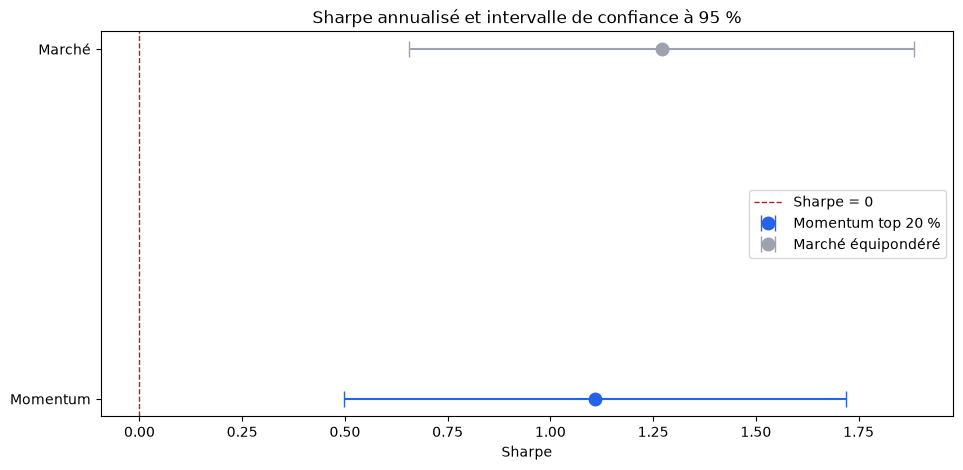

In [3]:
fig, ax = plt.subplots()
for i, (name, label, color) in enumerate([
    ('strategy', 'Momentum top 20 %', STRAT),
    ('benchmark', 'Marché équipondéré', BENCH),
]):
    row = ci.loc[name]
    ax.errorbar(row['sharpe'], i,
                xerr=[[row['sharpe'] - row['ci_bas']], [row['ci_haut'] - row['sharpe']]],
                fmt='o', color=color, capsize=6, markersize=9, label=label)
ax.axvline(0, color='firebrick', linestyle='--', linewidth=1, label='Sharpe = 0')
ax.set_yticks([0, 1], ['Momentum', 'Marché'])
ax.set(title='Sharpe annualisé et intervalle de confiance à 95 %', xlabel='Sharpe')
ax.legend();

**Lecture.** Les deux intervalles à 95 % sont loin de 0 (momentum : **[0,50 ; 1,72]** ; marché : **[0,66 ; 1,89]**) : les deux Sharpe sont **statistiquement significatifs**, ce ne sont pas des coups de chance. En revanche ils se **chevauchent largement** — avec 130 mois, on ne peut **pas** affirmer que le Sharpe du momentum (1,11) diffère de celui du marché (1,27). L'intervalle reste large : il faudrait bien plus de données pour trancher.

## 2. Sensibilité aux paramètres

On rejoue le backtest sur une grille `lookback` × `fraction retenue`. On veut une **zone** de bons résultats, pas un **pic isolé** : un pic = surajustement (on a trouvé le réglage chanceux).

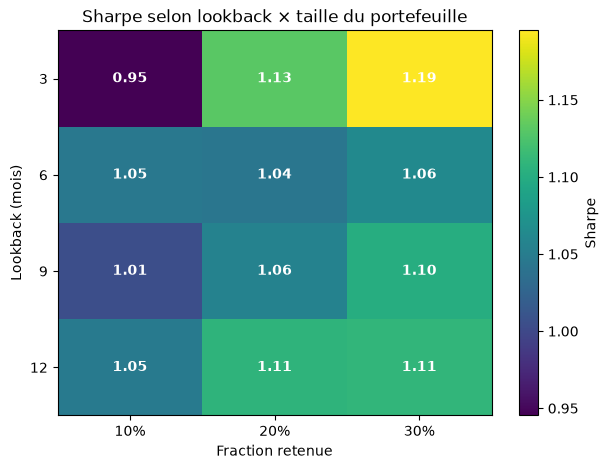

In [4]:
sweep = parameter_sweep(prices)
grid = sweep.pivot(index='lookback', columns='frac', values='sharpe')

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(grid, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(grid.columns)), [f'{c:.0%}' for c in grid.columns])
ax.set_yticks(range(len(grid.index)), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.annotate(f'{grid.values[i, j]:.2f}', (j, i), ha='center', va='center',
                    color='white', fontweight='bold', fontsize=10)
fig.colorbar(im, ax=ax, label='Sharpe')
ax.set(title='Sharpe selon lookback × taille du portefeuille',
       xlabel='Fraction retenue', ylabel='Lookback (mois)');

**Lecture.** Sur les 12 réglages, le Sharpe reste **entre 0,95 et 1,19** (moyenne ~1,07) : aucune case ne s'effondre, c'est un **plateau** et non un pic. La stratégie n'est donc pas surajustée à un réglage précis — le momentum « fonctionne » du lookback 3 à 12 et pour toutes les tailles de portefeuille testées. Le cas de base (12 mois, 20 %) à **1,11** est au milieu du nuage, pas cherry-pické. À noter : garder moins d'actions (10 %) pousse le **rendement** plus haut mais pas le Sharpe — plus de rendement, plus de risque.

## 3. Tenue hors-échantillon

On coupe la période en deux au **01/01/2021**. Si la stratégie marche avant mais s'effondre après, le signal ne tient pas hors échantillon.

In [5]:
split = split_performance(bt, '2021-01-01')
split

rendement_annuel  volatilite_annuelle  sharpe  \
plein            strategy              0.203                0.183   1.108   
                 benchmark             0.187                0.144   1.271   
in_sample        strategy              0.232                0.171   1.312   
                 benchmark             0.230                0.145   1.505   
hors_echantillon strategy              0.180                0.193   0.955   
                 benchmark             0.153                0.143   1.069   

                            max_drawdown  
plein            strategy         -0.179  
                 benchmark        -0.222  
in_sample        strategy         -0.179  
                 benchmark        -0.161  
hors_echantillon strategy         -0.169  
                 benchmark        -0.222

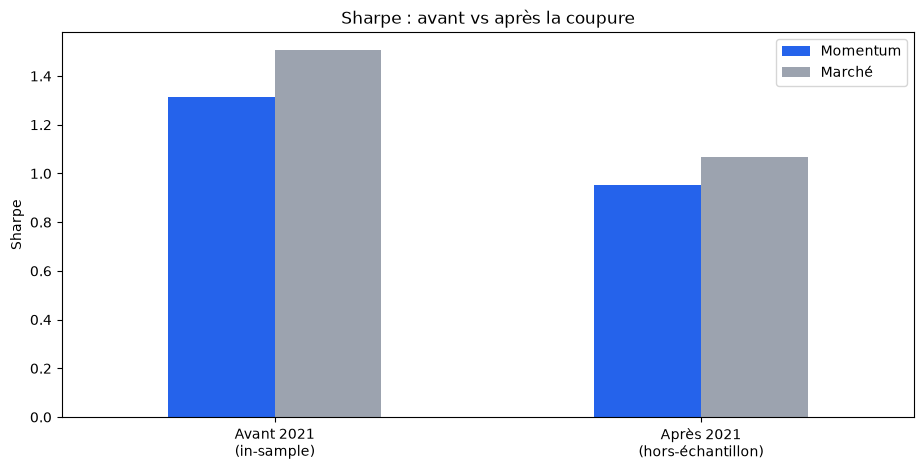

In [6]:
sharpe_split = split['sharpe'].unstack().loc[['in_sample', 'hors_echantillon']]
ax = sharpe_split.plot.bar(color=[STRAT, BENCH])
ax.set_xticklabels(['Avant 2021\n(in-sample)', 'Après 2021\n(hors-échantillon)'], rotation=0)
ax.set(title='Sharpe : avant vs après la coupure', ylabel='Sharpe', xlabel='')
ax.legend(['Momentum', 'Marché']);

**Lecture.** Comme attendu, tout baisse après la coupure (le Sharpe du momentum passe de **1,31 à 0,96**) — un backtest flatte toujours la période sur laquelle il a été construit. Mais l'essentiel tient : **hors échantillon**, le momentum garde un Sharpe positif, bat encore le marché en rendement (**18,0 %** vs 15,3 %) et conserve un meilleur drawdown. L'avantage **s'atténue mais ne disparaît pas** — signe que le signal n'est pas qu'un artefact de la première moitié.

## À retenir

- **Significatif mais pas supérieur** : le Sharpe du momentum est clairement > 0, mais son intervalle de confiance chevauche celui du marché — on ne peut pas prouver qu'il fait *mieux* que le marché en risque/rendement.
- **Pas surajusté** : le résultat est un plateau sur la grille de paramètres, pas un pic chanceux.
- **Tient hors échantillon**, avec un avantage atténué.
- Limites persistantes : **biais du survivant** (50 gagnantes d'aujourd'hui) et une seule coupure temporelle. Prochaine étape : le modèle ML (notebook `04`).